In [87]:
import pandas as pd
df=pd.read_csv('diabetes.csv')

In [88]:
df.shape

(768, 9)

In [89]:
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [90]:
for i in df.columns:
    print(df[i].isnull().mean()*100)

0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0


### There are no null values in the dataset

In [91]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


C:\Users\DC\AppData\Roaming\Python\Python313\site-packages\seaborn\categorical.py:3399: UserWarning: 51.7% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


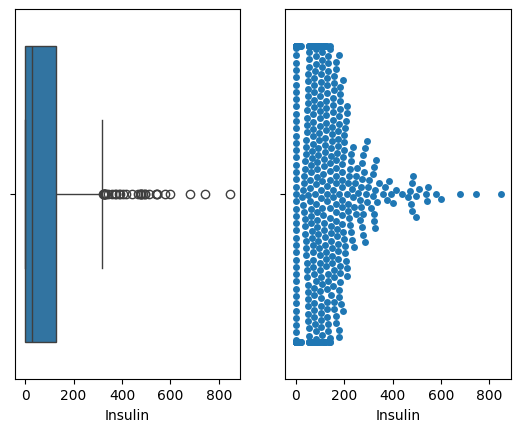

In [92]:
import seaborn as sns
import matplotlib.pyplot as plt
fig,axes=plt.subplots(1,2)
sns.boxplot(df,x='Insulin',ax=axes[0])
sns.swarmplot(df,x='Insulin',ax=axes[1])
plt.show()

In [93]:
df[df['Insulin']>600]

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
13,1,189,60,23,846,30.1,0.398,59,1
228,4,197,70,39,744,36.7,2.329,31,0
247,0,165,90,33,680,52.3,0.427,23,0


<Axes: xlabel='Outcome', ylabel='count'>

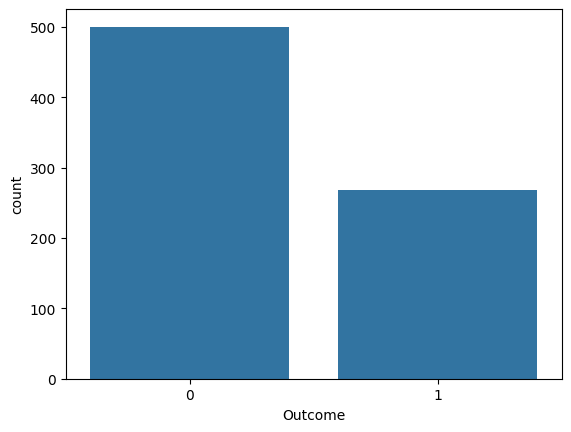

In [94]:
sns.countplot(df,x='Outcome')

In [95]:
df.duplicated().sum()

np.int64(0)

In [96]:
# separate input and output
x=df.iloc[:,:-1]
y=df['Outcome']

In [97]:
from sklearn.preprocessing import StandardScaler
ss=StandardScaler()
x=ss.fit_transform(x)

In [98]:
x

array([[ 0.63994726,  0.84832379,  0.14964075, ...,  0.20401277,
         0.46849198,  1.4259954 ],
       [-0.84488505, -1.12339636, -0.16054575, ..., -0.68442195,
        -0.36506078, -0.19067191],
       [ 1.23388019,  1.94372388, -0.26394125, ..., -1.10325546,
         0.60439732, -0.10558415],
       ...,
       [ 0.3429808 ,  0.00330087,  0.14964075, ..., -0.73518964,
        -0.68519336, -0.27575966],
       [-0.84488505,  0.1597866 , -0.47073225, ..., -0.24020459,
        -0.37110101,  1.17073215],
       [-0.84488505, -0.8730192 ,  0.04624525, ..., -0.20212881,
        -0.47378505, -0.87137393]], shape=(768, 8))

In [99]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [100]:
print(x_test.shape,y_test.shape)

(154, 8) (154,)


In [101]:
from sklearn.ensemble import RandomForestClassifier,AdaBoostClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
models={
    'logisticRegressor':LogisticRegression(),
    'RandomForest':RandomForestClassifier(),
    'SVM':SVC(),
    'ABR':AdaBoostClassifier()
}
train_scores={}
test_scores={}
for i in range(len(list(models))):
    model=list(models.values())[i]
    model.fit(x_train,y_train)
    y_train_pred=model.predict(x_train)
    y_test_pred=model.predict(x_test)
    train_acc_score=accuracy_score(y_train,y_train_pred)
    test_acc_score=accuracy_score(y_test,y_test_pred)
    train_scores[list(models.keys())[i]]=train_acc_score
    test_scores[list(models.keys())[i]]=test_acc_score
    print(f'For {list(models)[i]}: ')
    print('Training Score: ',train_acc_score,'\nTesting Score: ',test_acc_score)

For logisticRegressor: 
Training Score:  0.7703583061889251 
Testing Score:  0.7532467532467533
For RandomForest: 
Training Score:  1.0 
Testing Score:  0.7467532467532467
For SVM: 
Training Score:  0.8289902280130294 
Testing Score:  0.7272727272727273
For ABR: 
Training Score:  0.8029315960912052 
Testing Score:  0.7792207792207793


## Since AdaBoostClassifier perform quite well among all 

In [102]:
model=AdaBoostClassifier()
model.fit(x_train,y_train)

,"estimator estimator: object, default=NoneThe base estimator from which the boosted ensemble is built.Support for sample weighting is required, as well as proper``classes_`` and ``n_classes_`` attributes. If ``None``, thenthe base estimator is :class:`~sklearn.tree.DecisionTreeClassifier`initialized with `max_depth=1`... versionadded:: 1.2 `base_estimator` was renamed to `estimator`.",None
,"n_estimators n_estimators: int, default=50The maximum number of estimators at which boosting is terminated.In case of perfect fit, the learning procedure is stopped early.Values must be in the range `[1, inf)`.",50
,"learning_rate learning_rate: float, default=1.0Weight applied to each classifier at each boosting iteration. A higherlearning rate increases the contribution of each classifier. There isa trade-off between the `learning_rate` and `n_estimators` parameters.Values must be in the range `(0.0, inf)`.",1.0
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given at each `estimator` at eachboosting iteration.Thus, it is only used when `estimator` exposes a `random_state`.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",None
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels.","ndarray[int64](2,)","[0,1]"
estimator_ estimator_: estimatorThe base estimator from which the ensemble is grown... versionadded:: 1.2 `base_estimator_` was renamed to `estimator_`.,DecisionTreeClassifier,DecisionTreeC...r(max_depth=1)
estimator_errors_ estimator_errors_: ndarray of floatsClassification error for each estimator in the boostedensemble.,"ndarray[float64](50,)","[0.27,0.36,0.36,...,0.47,0.47,0.48]"
estimator_weights_ estimator_weights_: ndarray of floatsWeights for each estimator in the boosted ensemble.,"ndarray[float64](50,)","[1.02,0.57,0.58,...,0.12,0.11,0.08]"
estimators_ estimators_: list of classifiersThe collection of fitted sub-estimators.,list,"[DecisionTreeC...te=1714161693), DecisionTreeC...te=2004786067), DecisionTreeC...ate=366812083), DecisionTreeC...ate=260554577), ...]"
"feature_importances_ feature_importances_: ndarray of shape (n_features,)The impurity-based feature importances if supported by the``estimator`` (when based on decision trees).Warning: impurity-based feature importances can be misleading forhigh cardinality features (many unique values). See:func:`sklearn.inspection.permutation_importance` as an alternative.","ndarray[float64](8,)","[0. ,0.31,0.03,...,0.24,0.17,0.24]"


In [103]:
df.sample()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
81,2,74,0,0,0,0.0,0.102,22,0


In [104]:
import numpy as np
input_data=(5,	137,	108,	0,	0,	48.8,	0.227,	37)
input_data_reshaped=np.array(input_data).reshape(1,-1)
std_data=ss.transform(input_data_reshaped)
std_data

C:\Users\DC\AppData\Roaming\Python\Python313\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


array([[ 0.3429808 ,  0.5040552 ,  2.01075975, -1.28821221, -0.69289057,
         2.1331853 , -0.73955549,  0.31985461]])

In [105]:
prediction=model.predict(std_data)
print(prediction)
if prediction[0]==0:
    print('Person is not diabetic')
else:
    print('Person is diabetic')

[1]
Person is diabetic


In [106]:
df.sample()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
356,1,125,50,40,167,33.3,0.962,28,1


In [107]:
input_data=(4,	97,	60,	23,	0,	28.2,	0.443,	22	)
input_data_reshaped=np.array(input_data).reshape(1,-1)
std_data=ss.transform(input_data_reshaped)
std_data

C:\Users\DC\AppData\Roaming\Python\Python313\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


array([[ 0.04601433, -0.74783062, -0.47073225,  0.15453319, -0.69289057,
        -0.48135115, -0.08720986, -0.95646168]])

In [108]:
prediction=model.predict(std_data)
print(prediction)
if prediction[0]==0:
    print('Person is not diabetic')
else:
    print('Person is diabetic')

[0]
Person is not diabetic


In [109]:
import dill
with open('model.pkl','wb') as f:
    dill.dump(model,f)